<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PPCA Generative Model: x = Wz + μ + ε
Estimated Noise Variance: 0.9053101580604183
Reconstruction Error: 0.36139981509771885
Components: 1 Error: 0.7668
Components: 2 Error: 0.5509
Components: 3 Error: 0.3614
Components: 4 Error: 0.1749


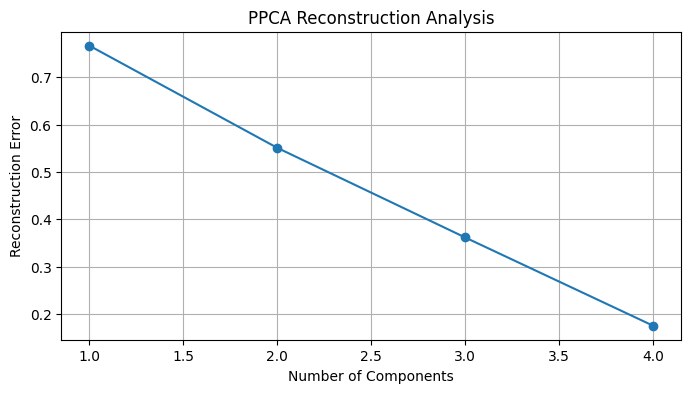


Generated Sensor Samples:
   Temperature  Vibration  Pressure  Current  Humidity
0        22.64      61.65    116.18    21.64     63.00
1        41.24      69.59     91.96    25.20     63.53
2        33.89      29.63     94.47    16.86     65.74
3        35.31      29.81     97.09    23.32     62.77
4        33.66      53.98    106.90    19.31     50.26
5        23.97      63.61    107.28    22.18     54.12
6        28.63      59.32     95.10    14.35     66.16
7        27.42      50.72    129.18    18.92     60.80
8        27.22      42.04    105.70    16.44     56.00
9        29.79      50.35    114.86    19.84     74.18


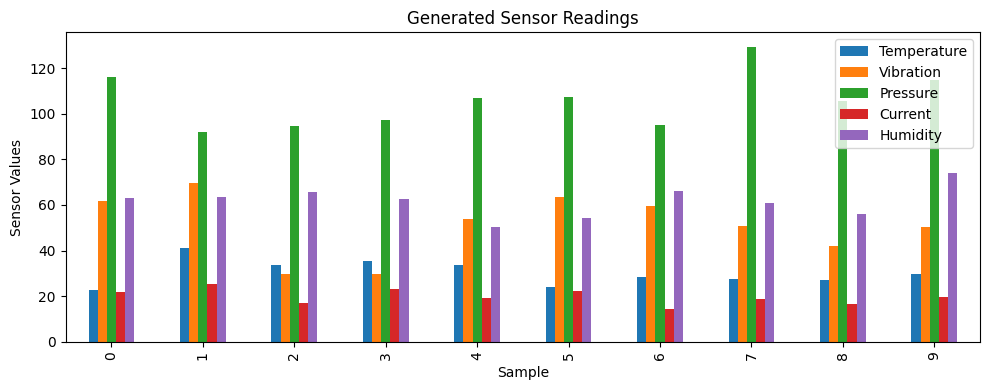

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# Generate small sensor dataset
np.random.seed(42)

data = pd.DataFrame({
    'Temperature': np.random.normal(30, 5, 500),
    'Vibration': np.random.normal(50, 10, 500),
    'Pressure': np.random.normal(100, 15, 500),
    'Current': np.random.normal(20, 4, 500),
    'Humidity': np.random.normal(60, 8, 500)
})

# Add Gaussian noise
noisy = data + np.random.normal(0, 2, data.shape)

# Add missing values
noisy.iloc[10:15, 2] = np.nan

# Handle missing values
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(noisy)

# Standardise data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Fit probabilistic PCA
pca = PCA(n_components=3)
pca.fit(X)

print("PPCA Generative Model: x = Wz + μ + ε")
print("Estimated Noise Variance:", pca.noise_variance_)

# Reconstruction
reduced = pca.transform(X)
reconstructed = pca.inverse_transform(reduced)

error = mean_squared_error(X, reconstructed)
print("Reconstruction Error:", error)

# Compare different components
errors = []

for k in range(1, 5):
    model = PCA(n_components=k)
    transformed = model.fit_transform(X)
    restored = model.inverse_transform(transformed)

    e = mean_squared_error(X, restored)
    errors.append(e)

    print("Components:", k, "Error:", round(e, 4))

# Plot reconstruction error
plt.figure(figsize=(8, 4))
plt.plot(range(1, 5), errors, marker='o')
plt.xlabel("Number of Components")
plt.ylabel("Reconstruction Error")
plt.title("PPCA Reconstruction Analysis")
plt.grid()
plt.show()

# Generate new samples from the fitted PPCA model
k = pca.n_components_

W = pca.components_.T * np.sqrt(
    np.maximum(pca.explained_variance_ - pca.noise_variance_, 0)
)

Z = np.random.normal(0, 1, (10, k))

noise = np.random.normal(
    0, np.sqrt(max(pca.noise_variance_, 0)), (10, X.shape[1])
)

new_samples = Z @ W.T + pca.mean_ + noise

# Convert to original scale
generated = scaler.inverse_transform(new_samples)

generated_df = pd.DataFrame(
    generated, columns=data.columns
)

print("\nGenerated Sensor Samples:")
print(generated_df.round(2))

generated_df.plot(kind='bar', figsize=(10, 4))
plt.title("Generated Sensor Readings")
plt.xlabel("Sample")
plt.ylabel("Sensor Values")
plt.tight_layout()
plt.show()